# Exposure at default and the credit conversion factor: the terminology trap

**Question:** When a document speaks of the credit conversion factor of a revolving line, which of three different ratios does it mean, and how far do the reference date and the treatment of the outliers move the factor of a generated book whose true factor is known?

- **Level:** 1, Fundamentals
- **Prerequisites:** notebook 01 of this topic (the workout LGD) and notebooks 01 and 02 of topic 01
- **Reading time:** about 35 minutes

## Objectives

By the end of this notebook you can:

- compute the exposure at default of a revolving line from a credit conversion factor, and go back from the EAD to the factor;
- say which of the three numbers called "the CCF" a document means: the EU factor on the undrawn amount, the US loan equivalent and the Qi (2009) ratios to the balance and to the limit;
- choose and read the three reference-date designs (fixed horizon, cohort, variable horizon) with `reference_indices` and `ccf_observations`, and say when a factor is undefined;
- treat a factor below 0 or above 1 in each of the four ways of `treat_ccf`, and say what each does to the mean;
- read the distribution of the factors of the C09 generator and the small-undrawn rule.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you.

In [1]:
# Put the pipeline on the import path, import the packages and print their versions
import importlib.metadata as md
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.lgd_ead import ccf, workout

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.c09 import estimators, generator, params

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Data

Two committed artifacts of case C09, the exposure at default and the conversion factor of revolving lines: `data/derived/C09/level-0.json` (the variant for acceleration level 0) and `data/derived/C09/models-generator.json` (the generator and the designs behind every level). C09 has **a known truth**. Its lines are produced by a generator whose field structure and marginal distributions follow the Federal Reserve's 2025 hypothetical card portfolios, and the generator draws balances with a conversion factor that is its own parameter. Every estimate is therefore shown beside the truth it should recover, and the data are synthetic, not observations of any lender.

Level 0 means no acceleration: the undrawn amount is drawn at a constant rate over the twelve months before the default. Notebooks 05 and 07 of this topic raise the level; here level 0 teaches the vocabulary. The artifacts hold the plan of the replications and the convention; the lines themselves are not committed, because the generator redraws them from a seed. Step 4 therefore draws one replication in the notebook, with the case's own generator in `data-pipeline/pipeline/cases/c09` and the first test seed of the committed plan: 50,000 facilities, of which a few thousand default. Nothing is written to disk.

In [2]:
# Open the two artifacts and print the engine version, the generator's notice and the three designs
derived = ROOT / "data" / "derived" / "C09"
level0 = json.loads((derived / "level-0.json").read_text(encoding="utf-8"))
gen = json.loads((derived / "models-generator.json").read_text(encoding="utf-8"))
out = level0["outputs"]
print("baked by riskvalidation:", level0["provenance"]["riskvalidation_version"])
print("installed:", rv.__version__)
print(out["generator"]["notice"]["en"])
print("convention:", out["convention"]["name"], "|", out["convention"]["formula"])
for design in gen["fit"]["designs"]:
    print("-", design["label"]["en"])

baked by riskvalidation: 1.0.1
installed: 1.0.1
Synthetic data: these are generated revolving credit lines, not observations of any portfolio and not evidence about any bank or card issuer. Their field structure and marginals follow the Federal Reserve's 2025 hypothetical card portfolios; the CCF each level draws balances with is the generator's own parameter, so every estimate is shown beside the truth it is meant to recover. Amounts in USD.
convention: eu-undrawn | CCF = (EAD - E(t_r)) / (L(t_r) - E(t_r))
- Fixed horizon: 12 months before default
- Yearly cohort: the cohort start
- Variable horizon: quarterly reference dates in the year before default


## Method

### Step 1: one facility, three numbers

A revolving line has a limit $L$ and a drawn balance $E$ at a reference date, and the bank's exposure at default is $EAD$. The research for this product records the EU convention as

$$CCF = \frac{EAD - E(t_r)}{L(t_r) - E(t_r)} \qquad\Longleftrightarrow\qquad EAD = E(t_r) + CCF\,\big(L(t_r) - E(t_r)\big)$$

with $t_r$ the reference date before the default date $t_d$: the share of the undrawn amount that is drawn by default. In US terms the same ratio is the loan equivalent (LEQ). Qi (2009) uses the same words for other ratios: his "CCF" is $EAD / E$ (over the balance) and his "EADF" is $EAD / L$ (over the limit). (Sources: the docstring of `riskvalidation.lgd_ead.ccf` at release 0.8.1, and Qi 2009, OCC Economics Working Paper 2009-2, as named there.) A document that says "the CCF" without naming the denominator can mean any of the three, and this is the terminology trap.

`to_us_terms(drawn, limit, ead)` returns the three numbers for each facility, and `ead_from_ccf(drawn, limit, ccf)` goes back. The next cell invents three facilities: a line that is part drawn at default, one that is fully drawn and one that is over its limit.

In [3]:
# Three invented facilities: the three numbers called the CCF, and the EAD recovered from the EU factor
names = ["part drawn", "fully drawn", "over the limit"]
drawn = np.array([60.0, 20.0, 90.0])
limit = np.array([100.0, 100.0, 100.0])
ead = np.array([85.0, 100.0, 120.0])

leq, ccf_us, eadf = ccf.to_us_terms(drawn, limit, ead)
print(f"{"":16s} {"E":>4s} {'L':>4s} {'EAD':>4s} | {'EU factor':>9s} | {'EAD/E':>7s} | {'EAD/L':>6s}")
for i, name in enumerate(names):
    head = f"{name:16s} {drawn[i]:4.0f} {limit[i]:4.0f} {ead[i]:4.0f}"
    print(f"{head} | {leq[i]:9.4f} | {ccf_us[i]:7.4f} | {eadf[i]:6.4f}")
print("EAD recovered from the EU factor:", ccf.ead_from_ccf(drawn, limit, leq))

                    E    L  EAD | EU factor |   EAD/E |  EAD/L
part drawn         60  100   85 |    0.6250 |  1.4167 | 0.8500
fully drawn        20  100  100 |    1.0000 |  5.0000 | 1.0000
over the limit     90  100  120 |    3.0000 |  1.3333 | 1.2000
EAD recovered from the EU factor: [ 85. 100. 120.]


The same facility is 0.625, 1.4167 and 0.85 depending on the ratio. The EU factor is exactly 1 for the fully drawn line (it drew all of its undrawn amount) and 3 for the line over its limit (the limit was 100, the balance 90, and the bank ended up 30 above the balance: three times the 10 that was undrawn). Notice what the factor does when the undrawn amount is small: a few currency units of undrawn amount in the denominator make the ratio explode, which is why step 5 comes back to it.

### Step 2: which month is the reference date?

The factor needs a reference date $t_r$ before the default, and the choice is a model design, not a detail. The engine's `reference_indices(design, default_index, ...)` gives the months of a facility's path for each design:

- `fixed-horizon`: one date, `horizon` months before the default (`t_d - h`);
- `cohort`: one date, the start of the calendar cohort that contains the default (the caller gives `cohort_start_index`);
- `variable-horizon`: `n_reference` dates, `t_d - h + k * step` for `k = 0 ... n_reference - 1`.

(Source: the docstring of `reference_indices`; the three designs follow Moral (2006) as the research summarises it, and the engine marks the detail UNVERIFIED because that chapter was not read.) A reference date that is negative or not before the default raises an error. `ccf_observations(drawn, limit, ead, reference_index)` then returns the factor and the undrawn amount at each date, and `aggregate_ccf` combines them as the mean of the factors or as the pooled ratio $\sum (CCF\,U) / \sum U$ of the undrawn amounts $U$.

The next cell invents the monthly path of one line that defaults at month 20 with an EAD of 88, and of a second line that is fully drawn from month 14. It prints the months each design picks and the factor each gives.

In [4]:
# Two invented monthly paths: the reference months of each design, the factors and their two aggregations
limit_path = np.full(21, 100.0)
drawn_a = np.linspace(30.0, 85.0, 21)
drawn_b = np.minimum(np.linspace(40.0, 130.0, 21), 100.0)
default_month = 20
shown = {"fixed-horizon": "fixed horizon", "cohort": "cohort",
         "variable-horizon": "variable horizon"}
designs = {"fixed-horizon": dict(horizon=12), "cohort": dict(cohort_start_index=12),
           "variable-horizon": dict(horizon=12, n_reference=4, step=3)}
paths = (("line 1, EAD 88", drawn_a, 88.0),
         ("line 2 (fully drawn from month 14), EAD 100", drawn_b, 100.0))
for label, path, final_ead in paths:
    print(label)
    for design, kwargs in designs.items():
        idx = ccf.reference_indices(design, default_month, **kwargs)
        factors, undrawn = ccf.ccf_observations(path, limit_path, final_ead, idx)
        print(f"  {shown[design]:18s} months {idx.tolist()} factors {np.round(factors, 4).tolist()}")
        if np.isfinite(factors).any():
            mean = ccf.aggregate_ccf(factors, undrawn, "mean")
            pooled = ccf.aggregate_ccf(factors, undrawn, "pooled")
            print(f"  {'':18s} mean {mean:.4f} pooled {pooled:.4f}")

line 1, EAD 88
  fixed horizon      months [8] factors [0.75]
                     mean 0.7500 pooled 0.7500
  cohort             months [12] factors [0.6757]
                     mean 0.6757 pooled 0.6757
  variable horizon   months [8, 11, 14, 17] factors [0.75, 0.6981, 0.619, 0.4839]
                     mean 0.6378 pooled 0.6632
line 2 (fully drawn from month 14), EAD 100
  fixed horizon      months [8] factors [1.0]
                     mean 1.0000 pooled 1.0000
  cohort             months [12] factors [1.0]
                     mean 1.0000 pooled 1.0000
  variable horizon   months [8, 11, 14, 17] factors [1.0, 1.0, nan, nan]
                     mean 1.0000 pooled 1.0000


Two things to read in the output. First, line 1 gives a different factor under each design: 0.75 at the fixed horizon, 0.6757 at the cohort start, and 0.6378 (mean) or 0.6632 (pooled) for the variable horizon. In this invented path the balance keeps growing towards the default, so a later reference date leaves less undrawn amount and the same EAD is a smaller share of it. The factor is a property of the design as much as of the line, and C09 measures that on a known truth in notebook 05. Second, for the second line the months where the balance has reached the limit give `nan`: when the undrawn amount is not positive the factor is undefined, and the engine says so with a missing value, never with 0 or 1. A defaulter whose every reference month is fully drawn simply has no factor, and C09 counts those defaulters.

### Step 3: a factor below 0 or above 1

A factor below 0 means the balance fell between the reference date and the default; above 1 means the bank ended above the limit. Both happen. `treat_ccf(ccf, treatment)` offers four treatments and reports what it did:

- `none`: keep every value (flag them with `range_flag`);
- `censor`: drop the observations outside [0, 1];
- `floor-cap`: clip to [0, 1], which the engine documents as biasing the EAD;
- `bounded-scale`: return the clipped values as the response of a fractional logit.

Missing factors are dropped first and counted, and the counts of values below 0 and above 1 are taken on the input whatever the treatment. The next cell applies the four treatments to eight invented factors.

In [5]:
# Flag eight invented factors and apply the four treatments of treat_ccf
factors = np.array([-0.40, 0.10, 0.35, 0.60, 0.80, 1.00, 1.70, np.nan])
word = {"below-zero": "below 0", "in-range": "in [0, 1]", "above-one": "above 1"}
flagged = workout.range_flag(np.nan_to_num(factors, nan=0.5))
print("range_flag:", [word[str(f)] for f in flagged])
for treatment in ccf.TREATMENTS:
    t = ccf.treat_ccf(factors, treatment)
    print(f"{treatment:14s} kept {t.values.size} dropped {t.n_dropped}"
          f" below 0 {t.n_below_zero} above 1 {t.n_above_one} mean factor {t.values.mean():.4f}")

range_flag: ['below 0', 'in [0, 1]', 'in [0, 1]', 'in [0, 1]', 'in [0, 1]', 'in [0, 1]', 'above 1', 'in [0, 1]']
none           kept 7 dropped 1 below 0 1 above 1 1 mean factor 0.5929
censor         kept 5 dropped 3 below 0 1 above 1 1 mean factor 0.5700
floor-cap      kept 7 dropped 1 below 0 1 above 1 1 mean factor 0.5500
bounded-scale  kept 7 dropped 1 below 0 1 above 1 1 mean factor 0.5500


### Step 4: the factors of a generated book of revolving lines

Now the generator of C09 at level 0, where the true factor is fixed by the parameters: `params.known_ccf(0, 12)`, the share of the undrawn amount that a defaulter draws in the last twelve months, averaged over the defaulters. The cell draws one replication, reads the fixed-horizon factor of each defaulter with `reference_indices` and `ccf_observations` (through the case's `observe`), summarises the factors with `aggregate_ccf` as a mean and as a pooled ratio, and counts the factors below 0 and above 1 with `treat_ccf`. The bias is the signed difference between an estimate and the truth, `ccf_bias(estimate, truth)`.

In [6]:
# Draw one replication at level 0 and summarise the fixed-horizon factors of its defaulters
seed = gen["fit"]["replications_plan"]["test_seeds"][0]
book = generator.generate(seed, 0, 50_000)
obs = estimators.observe(book, "fixed-horizon")
truth = params.known_ccf(0, 12)
defined = np.isfinite(obs.ccf)
n_book = book.n_defaults
print(f"defaulters: {n_book:,} | with a defined factor: {defined.sum():,}")
print(f"known CCF of level 0: {truth:.4f}")
for aggregator in ("mean", "pooled"):
    value = ccf.aggregate_ccf(obs.ccf, obs.undrawn, aggregator)
    print(f"{aggregator:7s} {value:.4f} | bias {ccf.ccf_bias(value, truth):+.4f}")
kept = ccf.treat_ccf(obs.ccf, "none")
print(f"below 0: {kept.n_below_zero} ({kept.n_below_zero / defined.sum():.2%})")
print(f"above 1: {kept.n_above_one} ({kept.n_above_one / defined.sum():.2%})")

defaulters: 1,894 | with a defined factor: 1,503
known CCF of level 0: 0.6000
mean    0.5932 | bias -0.0068
pooled  0.5704 | bias -0.0296
below 0: 24 (1.60%)
above 1: 102 (6.79%)


The factors are in memory; the next cell draws their distribution with the known CCF as a dashed line and the pooled estimate as a dotted one, and clips the display at -0.5 and 2 so that a few extreme values do not stretch the axis.

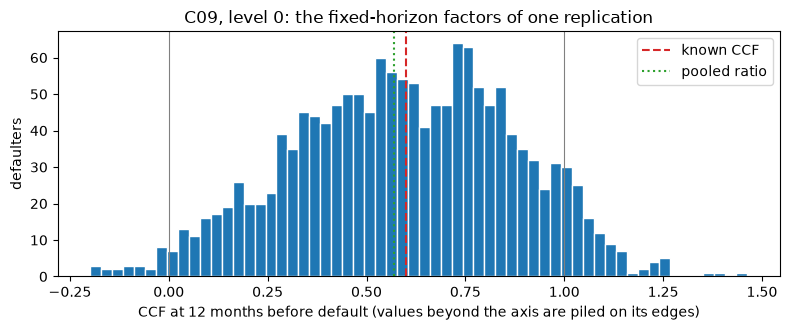

In [7]:
# Draw the distribution of the factors with the known CCF and the two estimates marked
pooled = ccf.aggregate_ccf(obs.ccf, obs.undrawn, "pooled")
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(np.clip(obs.ccf[defined], -0.5, 2.0), bins=60, color="tab:blue", edgecolor="white")
ax.axvline(truth, color="tab:red", linestyle="--", label="known CCF")
ax.axvline(pooled, color="tab:green", linestyle=":", label="pooled ratio")
ax.axvline(0.0, color="grey", linewidth=0.8)
ax.axvline(1.0, color="grey", linewidth=0.8)
ax.set_xlabel("CCF at 12 months before default (values beyond the axis are piled on its edges)")
ax.set_ylabel("defaulters")
ax.set_title("C09, level 0: the fixed-horizon factors of one replication")
ax.legend()
fig.tight_layout()
plt.show()

The bulk of the factors lies between 0 and 1 and centres near the known 0.6, as it should, but the histogram has two features that a single summary hides: a visible mass at 1 and beyond, the lines that drew their whole undrawn amount or ended above the limit, and a thin tail below 0, the lines whose balance fell. The pooled ratio, drawn as the dotted line, sits to the left of the truth because it gives weight to the undrawn currency, and the lines with a large undrawn amount draw proportionally less. Neither summary is wrong; they answer two different questions, which is why a validator asks for the aggregation along with the factor.

### Step 5: when the undrawn amount is small

If a line has only a few currency units undrawn at the reference date, the ratio $(EAD - E)/(L - E)$ divides by almost nothing and is unstable. Qi (2009) switches to a different ratio below a threshold of undrawn amount; `small_undrawn_rule(drawn, limit, ead, threshold)` returns which facilities are switched and the ratio to use: $EAD/L$ where switched, the EU factor elsewhere. The threshold is a parameter in the currency of the amounts. The next cell applies it first to three invented facilities, two of them with less than 50 undrawn, and then to the defaulters of the replication of step 4 at a threshold of 50 USD, and prints whether the committed factors of the artifact apply the rule.

In [8]:
# Apply the small-undrawn rule to three invented facilities and to the defaulters of the generated book
d = np.array([4_980.0, 4_000.0, 1_000.0])
lim = np.array([5_000.0, 4_030.0, 5_000.0])
e = np.array([5_020.0, 4_100.0, 3_000.0])
switched, ratio = ccf.small_undrawn_rule(d, lim, e, threshold=50.0)
for i in range(3):
    print(f"facility {i + 1}: undrawn {lim[i] - d[i]:7.1f}"
          f" switched {bool(switched[i])!s:5s} ratio used {ratio[i]:.4f}")

flag, _ = ccf.small_undrawn_rule(obs.drawn_ref[defined], obs.limit_ref[defined], obs.ead[defined], threshold=50.0)
print(f"generated defaulters switched at 50 USD: {flag.sum():,} of {defined.sum():,}")
small = out["small_undrawn"]
print(f"artifact: rule applied to the committed factors: {small['applied']}")

facility 1: undrawn    20.0 switched True  ratio used 1.0040
facility 2: undrawn    30.0 switched True  ratio used 1.0174
facility 3: undrawn  4000.0 switched False ratio used 0.5000
generated defaulters switched at 50 USD: 19 of 1,503
artifact: rule applied to the committed factors: False


## Results

**Answer:** The part-drawn line of the example has an EU factor of 0.6250, a ratio to the balance of 1.4167 and a ratio to the limit of 0.8500, so a document that says "the CCF" without naming the denominator can mean any of the three. On a generated book whose true factor is 0.6000, the EU factor at the 12-month horizon averages 0.5932 over 1,503 defaulters (a bias of -0.0068) and pools to 0.5704 (-0.0296); the reference date alone moves one invented line from 0.7500 to 0.6757, and the treatment of the outliers moves eight invented factors from a mean of 0.5929 to 0.5700 (censored) or 0.5500 (clipped).

- **One facility, three numbers.** The part-drawn line (balance 60, limit 100, EAD 85) has an EU factor of 0.6250, a ratio to the balance of 1.4167 and a ratio to the limit of 0.8500. The fully drawn line has a ratio to the balance of 5.0000 and the line over its limit an EU factor of 3.0000. `ead_from_ccf` returns the three invented EADs (85, 100 and 120) from the EU factors, so the identity runs both ways.
- **The reference date is a design.** For line 1 the fixed-horizon factor is 0.7500, the cohort-start factor 0.6757 and the variable-horizon factor 0.6378 as a mean and 0.6632 pooled. For line 2 the months where the balance had reached the limit give a missing factor, not a 0 or a 1.
- **Treating a factor outside [0, 1] changes the mean.** On eight invented factors, keeping all gives 0.5929, censoring gives 0.5700 (it drops three observations: the one below 0, the one above 1 and the missing one) and flooring and capping, or the bounded scale, gives 0.5500.
- **A generated book has factors outside [0, 1] and a known centre.** Of 1,894 defaulters, 1,503 have a defined factor at the 12-month horizon; 24 (1.60%) are below 0 and 102 (6.79%) above 1, around a known CCF of 0.6000. The mean of the factors misses it by -0.0068 and the pooled ratio by -0.0296.
- **The small-undrawn rule is a switch.** At a threshold of 50 USD it moves 19 of the 1,503 generated defaulters to the ratio to the limit, and the committed factors of the artifact do not apply it.

What the notebook does not do: it does not say which convention a regulator or a bank should use, only what each one means. The three invented facilities and the two paths exist to show the arithmetic and carry no information about any lender, and the generated book is one replication, so its biases are one draw and not the average over twenty that notebook 05 reports. The next notebook returns to LGD and fits the ladder of models on the C08 cohorts.

## Summary

- The EU factor is $(EAD - E)/(L - E)$, the share of the undrawn amount drawn by default; Qi (2009) uses "CCF" for $EAD/E$ and "EADF" for $EAD/L$. `to_us_terms` returns all three so a page never mixes them.
- The reference date is a design: `reference_indices` gives the months of the fixed-horizon, cohort and variable-horizon designs, and `ccf_observations` returns a factor and an undrawn amount at each.
- A factor is undefined (a missing value, never 0 or 1) when the line is fully drawn or over its limit at the reference date.
- A factor outside [0, 1] is real; `treat_ccf` keeps, censors, clips or bounds it, and reports the counts.
- C09 is a generator with a known CCF, so each estimate in the later notebooks is judged against the truth. The small-undrawn rule is a parameterised switch that the baked factors do not apply.

**What to try next.** Change the default month or the path in step 2 and see how the factor moves with the design; then continue with notebook 03, the ladder of LGD models fitted on the C08 cohorts.

## References

- BCBS, Basel Framework, CRE32 (internal ratings-based approach; the supervisory conversion factors and the EAD floor are applied in notebook 04). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- BCBS (2017), Basel III: Finalising post-crisis reforms (d424). https://www.bis.org/bcbs/publ/d424.htm
- Qi, M. (2009), Exposure at default of unsecured credit cards, OCC Economics Working Paper 2009-2: the ratios to the balance and to the limit, and the switch below a small undrawn amount, as named in the engine's documentation of `riskvalidation.lgd_ead.ccf`.
- Moral, G. (2006), the three reference-date designs, as summarised in the research for this product and in the docstring of `reference_indices` (the chapter was not read: detail UNVERIFIED).
- This repository: `docs/design/SDD.md` (case C09, a generator with a known truth) and `data/derived/C09/level-0.json`.